# Banking Loan Analysis Report

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

import warnings 
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_excel('financial_loan.xlsx')

In [3]:
df.head()

,id,address_state,application_type,emp_length,emp_title,grade,home_ownership,issue_date,last_credit_pull_date,last_payment_date,...,sub_grade,term,verification_status,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
0,1077430,GA,INDIVIDUAL,< 1 year,Ryder,C,RENT,2021-02-11,2021-09-13,2021-04-13,...,C4,60 months,Source Verified,30000.0,0.0100,59.83,0.1527,2500,4,1009
1,1072053,CA,INDIVIDUAL,9 years,MKC Accounting,E,RENT,2021-01-01,2021-12-14,2021-01-15,...,E1,36 months,Source Verified,48000.0,0.0535,109.43,0.1864,3000,4,3939
2,1069243,CA,INDIVIDUAL,4 years,Chemat Technology Inc,C,RENT,2021-01-05,2021-12-12,2021-01-09,...,C5,36 months,Not Verified,50000.0,0.2088,421.65,0.1596,12000,11,3522
3,1041756,TX,INDIVIDUAL,< 1 year,barnes distribution,B,MORTGAGE,2021-02-25,2021-12-12,2021-03-12,...,B2,60 months,Source Verified,42000.0,0.0540,97.06,0.1065,4500,9,4911
4,1068350,IL,INDIVIDUAL,10+ years,J&J Steel Inc,A,MORTGAGE,2021-01-01,2021-12-14,2021-01-15,...,A1,36 months,Verified,83000.0,0.0231,106.53,0.0603,3500,28,3835


In [4]:
df.tail()

,id,address_state,application_type,emp_length,emp_title,grade,home_ownership,issue_date,last_credit_pull_date,last_payment_date,...,sub_grade,term,verification_status,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
38571,803452,NJ,INDIVIDUAL,< 1 year,Joseph M Sanzari Company,C,MORTGAGE,2021-07-11,2021-05-16,2021-05-16,...,C1,60 months,Verified,100000.0,0.1986,551.64,0.1299,24250,33,31946
38572,970377,NY,INDIVIDUAL,8 years,Swat Fame,C,RENT,2021-10-11,2021-04-16,2021-05-16,...,C1,60 months,Verified,50000.0,0.0458,579.72,0.1349,25200,18,31870
38573,875376,CA,INDIVIDUAL,5 years,Anaheim Regional Medical Center,D,RENT,2021-09-11,2021-05-16,2021-05-16,...,D5,60 months,Verified,65000.0,0.1734,627.93,0.1749,25000,20,35721
38574,972997,NY,INDIVIDUAL,5 years,Brooklyn Radiology,D,RENT,2021-10-11,2021-05-16,2021-05-16,...,D5,60 months,Verified,368000.0,0.0009,612.72,0.1825,24000,9,33677
38575,682952,NY,INDIVIDUAL,4 years,Allen Edmonds,F,RENT,2021-07-11,2021-05-16,2021-05-16,...,F3,60 months,Verified,80000.0,0.0600,486.86,0.2099,18000,7,27679


In [5]:
df.dtypes

id                                int64
address_state                       str
application_type                    str
emp_length                          str
emp_title                        object
grade                               str
home_ownership                      str
issue_date               datetime64[us]
last_credit_pull_date    datetime64[us]
last_payment_date        datetime64[us]
loan_status                         str
next_payment_date        datetime64[us]
member_id                         int64
purpose                             str
sub_grade                           str
term                                str
verification_status                 str
annual_income                   float64
dti                             float64
installment                     float64
int_rate                        float64
loan_amount                       int64
total_acc                         int64
total_payment                     int64
dtype: object

# KPI Analysis

#### 1) Total Loan Application 

In [6]:
total_loan_application = df['id'].count()
print("Total Loan Applications: ", total_loan_application)

Total Loan Applications:  38576


#### 2) MTD Total Loan Application 

In [7]:
latest_issue_date = df['issue_date'].max()
latest_year = latest_issue_date.year
latest_month = latest_issue_date.month

mtd_data = df[(df['issue_date'].dt.year == latest_year) & (df['issue_date'].dt.month == latest_month)]
mtd_loan_application = mtd_data['id'].count()
print(f"MTD Application (for {latest_issue_date.strftime ('%B %Y ')}) : " , mtd_loan_application)

MTD Application (for December 2021 ) :  4314


#### 3) Total Funded Amount

In [8]:
total_funded_amount = df['loan_amount'].sum() 
total_funded_amount_millions = total_funded_amount / 1000000
print("Total Funded Amount: ${:.2f}M" .format(total_funded_amount_millions))

Total Funded Amount: $435.76M


#### 4) MTD Total Funded Amount

In [9]:
latest_issue_date = df['issue_date'].max()
latest_year = latest_issue_date.year
latest_month = latest_issue_date.month

mtd_data = df[(df['issue_date'].dt.year == latest_year) & (df['issue_date'].dt.month == latest_month)]
mtd_fund_amount_millions = mtd_data['loan_amount'].sum() / 1000000
print("MTD Funds Amount {:.2f} M". format(mtd_fund_amount_millions))

MTD Funds Amount 53.98 M


#### 5) Total Amount Received

In [10]:
total_amount_received_millions = df['total_payment'].sum() / 1000000
print("Total Amount Received {:.2f} M" .format(total_amount_received_millions))

Total Amount Received 473.07 M


##### 6) MTD Total Amount Received

#### 7) Average Interest Rate

In [11]:
average_interest_rate = df['int_rate'].mean() * 100
print('Average Interest: {:.2f}%'.format(average_interest_rate))

Average Interest: 12.05%


#### 8) Average dti rate

In [12]:
average_dti_rate = df['dti'].mean() * 100
print('Average DTI Rate: {:.2f}%'.format(average_dti_rate))

Average DTI Rate: 13.33%


#### Good Loan Metrics

In [13]:
good_loans = df[df['loan_status'].isin(['Fully Paid' , "Current"])]

total_loan_application = df['id'].count()

good_loan_applications = good_loans['id'].count()
good_loans_funded_amount_millions = good_loans['loan_amount'].sum() / 1000000
good_loan_amount_received_millions = good_loans['total_payment'].sum() / 1000000

good_loan_percentage = (good_loan_applications / total_loan_application) * 100 

print("Total Good Loan Applications: ",good_loan_applications)
print("Total Good loan Funds Amount: {:.2f}M".format(good_loans_funded_amount_millions))
print("Total Good loan Amount Received Millions: {:.2f}M".format(good_loan_amount_received_millions))
print("Good Loan Percentage: {:.2f}%".format(good_loan_percentage))

Total Good Loan Applications:  33243
Total Good loan Funds Amount: 370.22M
Total Good loan Amount Received Millions: 435.79M
Good Loan Percentage: 86.18%


#### Bad Loan metrics

In [14]:
bad_loans = df[~ df['loan_status'].isin(['Fully Paid' , "Current"])]

total_loan_application = df['id'].count() 

bad_loan_applications = bad_loans['id'].count()
bad_loans_funded_amount_millions = bad_loans['loan_amount'].sum() / 1000000
bad_loan_amount_received_millions = bad_loans['total_payment'].sum() / 1000000

bad_loan_percentage = (bad_loan_applications / total_loan_application) * 100 

print("Total Good Loan Applications: ",bad_loan_applications)
print("Total Good loan Funds Amount: {:.2f}M".format(bad_loans_funded_amount_millions))
print("Total Good loan Amount Received Millions: {:.2f}M".format(bad_loan_amount_received_millions))
print("Good Loan Percentage: {:.2f}%".format(bad_loan_percentage))

Total Good Loan Applications:  5333
Total Good loan Funds Amount: 65.53M
Total Good loan Amount Received Millions: 37.28M
Good Loan Percentage: 13.82%


#### Monthly Trend Visualisation

###### 1) Monthly Funded Amount Visualisation

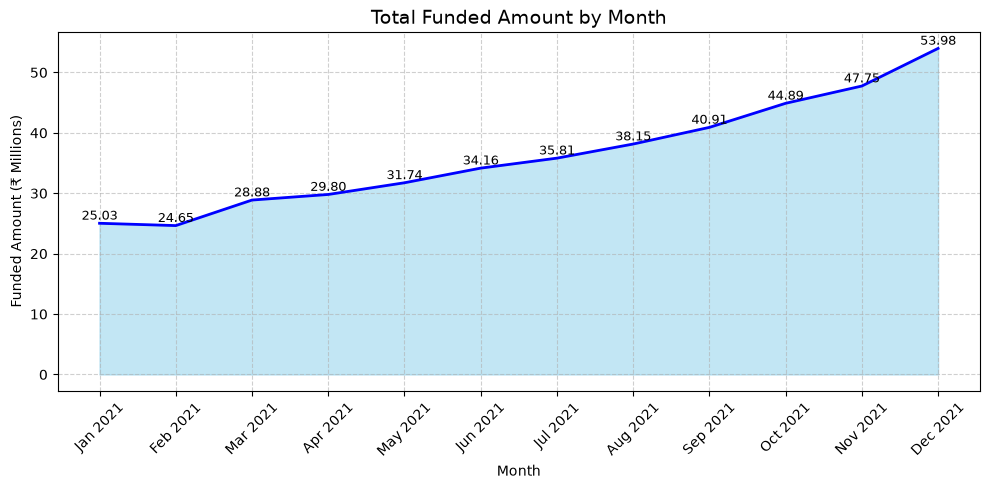

In [15]:
monthly_funded = (
    df.sort_values('issue_date')
      .assign(month_name=lambda x: x['issue_date'].dt.strftime('%b %Y'))
      .groupby('month_name', sort=False)['loan_amount']
      .sum()
      .div(1000000)
      .reset_index(name='loan_amount_millions')
)

plt.figure(figsize=(10, 5))
plt.fill_between(monthly_funded['month_name'], monthly_funded['loan_amount_millions'], color='skyblue', alpha=0.5)
plt.plot(monthly_funded['month_name'], monthly_funded['loan_amount_millions'], color='blue', linewidth=2)

for i, row in monthly_funded.iterrows():
    plt.text(i, row['loan_amount_millions'] + 0.1, f"{row['loan_amount_millions']:.2f}",
             ha='center', va='bottom', fontsize=9, rotation=0, color='black')

plt.title('Total Funded Amount by Month', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Funded Amount (₹ Millions)')
plt.xticks(ticks=range(len(monthly_funded)), labels=monthly_funded['month_name'], rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

###### 2) Monthly Received Amount Visualisation

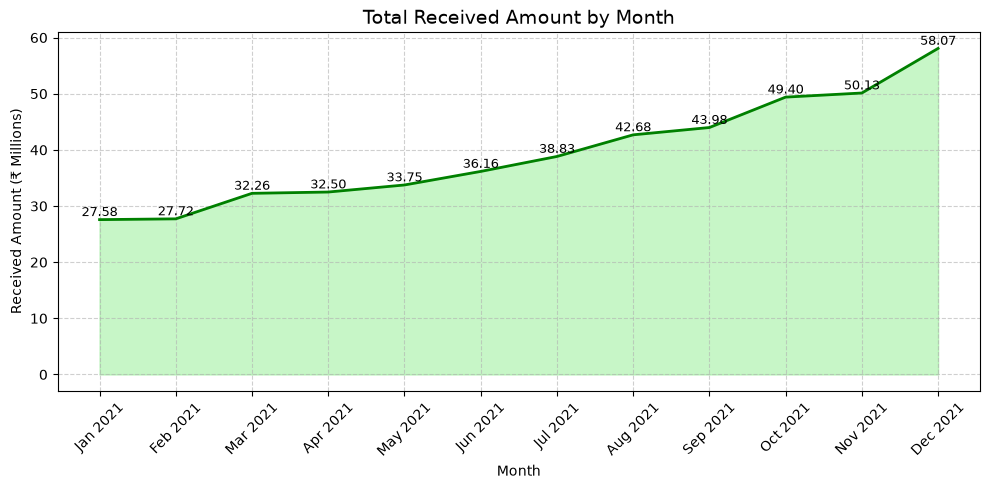

In [16]:
monthly_received = (
    df.sort_values('issue_date')
      .assign(month_name=lambda x: x['issue_date'].dt.strftime('%b %Y'))
      .groupby('month_name', sort=False)['total_payment']
      .sum()
      .div(1000000)
      .reset_index(name='amount_received_millions')
)

plt.figure(figsize=(10, 5))
plt.fill_between(monthly_received['month_name'], monthly_received['amount_received_millions'], color='lightgreen', alpha=0.5)
plt.plot(monthly_received['month_name'], monthly_received['amount_received_millions'], color='green', linewidth=2)

for i, row in monthly_received.iterrows():
    plt.text(i, row['amount_received_millions'] + 0.1, f"{row['amount_received_millions']:.2f}",
             ha='center', va='bottom', fontsize=9, rotation=0, color='black')

plt.title('Total Received Amount by Month', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Received Amount (₹ Millions)')
plt.xticks(ticks=range(len(monthly_received)), labels=monthly_received['month_name'], rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### 3) Monthly Loan Application Visualisation

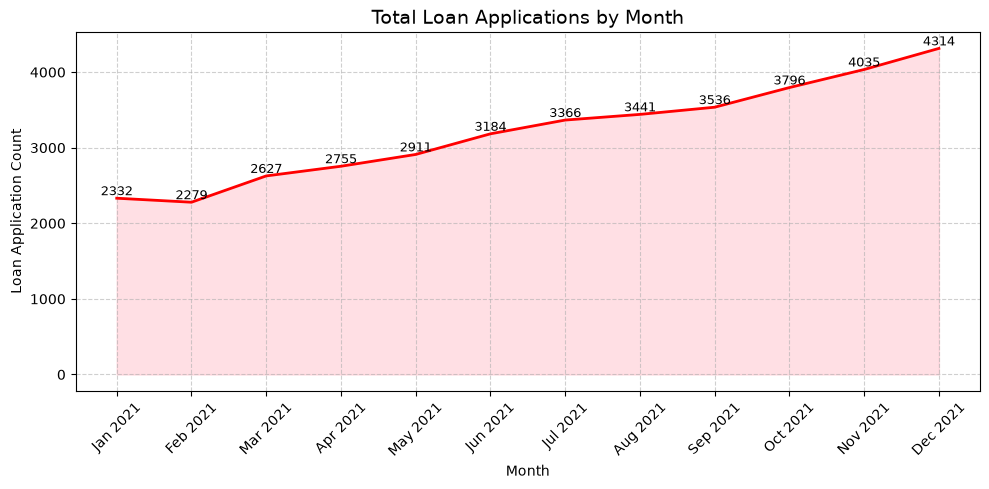

In [17]:
monthly_applications = (
    df.sort_values('issue_date')
      .assign(month_name=lambda x: x['issue_date'].dt.strftime('%b %Y'))
      .groupby('month_name', sort=False)['id']
      .count()
      .reset_index(name='loan_applications')
)

plt.figure(figsize=(10, 5))
plt.fill_between(monthly_applications['month_name'], monthly_applications['loan_applications'], color='pink', alpha=0.5)
plt.plot(monthly_applications['month_name'], monthly_applications['loan_applications'], color='red', linewidth=2)

for i, row in monthly_applications.iterrows():
    plt.text(i, row['loan_applications'] + 0.1, f"{row['loan_applications']}",
             ha='center', va='bottom', fontsize=9, rotation=0, color='black')

plt.title('Total Loan Applications by Month', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Loan Application Count')
plt.xticks(ticks=range(len(monthly_applications)), labels=monthly_applications['month_name'], rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### 3) Regional Analysis By State for total funded amount

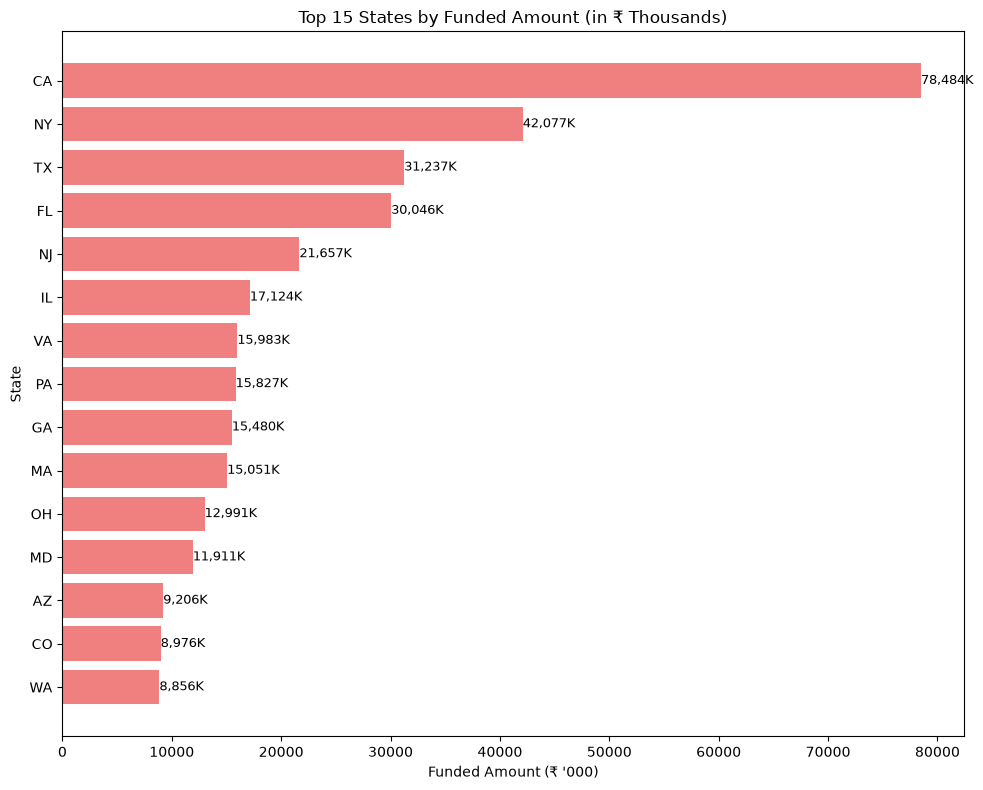

In [18]:
state_funding = df.groupby('address_state')['loan_amount'].sum().nlargest(15).sort_values(ascending = True)

state_funding_thousands = state_funding / 1000

plt.figure(figsize=(10, 8))
bars = plt.barh(
    state_funding_thousands.index,
    state_funding_thousands.values,
    color='lightcoral'
)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 10,
        bar.get_y() + bar.get_height() / 2,
        f'{width:,.0f}K',
        va='center',
        fontsize=9
    )

plt.title('Top 15 States by Funded Amount (in ₹ Thousands)')
plt.xlabel('Funded Amount (₹ \'000)')
plt.ylabel('State')
plt.tight_layout()
plt.show()

### 4) Loan Term Analysis by Funded Amount

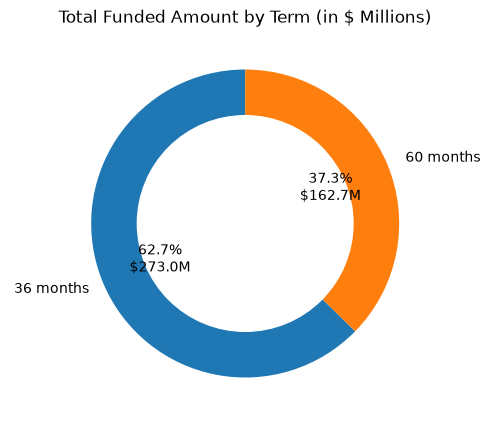

In [19]:
term_funding_millions = df.groupby('term')['loan_amount'].sum() / 1000000

plt.figure(figsize=(5, 5))
plt.pie(
    term_funding_millions,
    labels=term_funding_millions.index,
    autopct=lambda p: f"{p:.1f}%\n${p*sum(term_funding_millions)/100:.1f}M",
    startangle=90,
    wedgeprops={'width': 0.4}
)
plt.gca().add_artist(plt.Circle((0, 0), 0.70, color='white'))
plt.title("Total Funded Amount by Term (in $ Millions)")
plt.show()

###  5) Employee length By Funded Amount

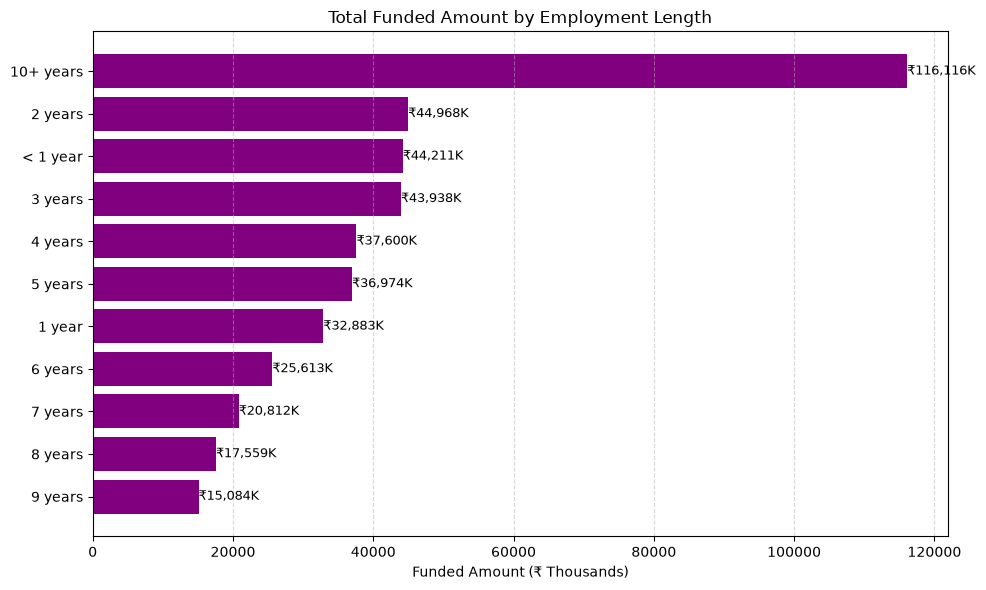

In [22]:
emp_funding_thousands = df.groupby('emp_length')['loan_amount'].sum().sort_values()/1000

plt.figure(figsize=(10, 6))
bars = plt.barh(emp_funding_thousands.index, emp_funding_thousands, color='purple')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 5, bar.get_y() + bar.get_height() / 2,
             f"₹{width:,.0f}K", va='center', fontsize=9)

plt.xlabel("Funded Amount (₹ Thousands)")
plt.title("Total Funded Amount by Employment Length")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 6) Loan Purpose By Funded Amount¶

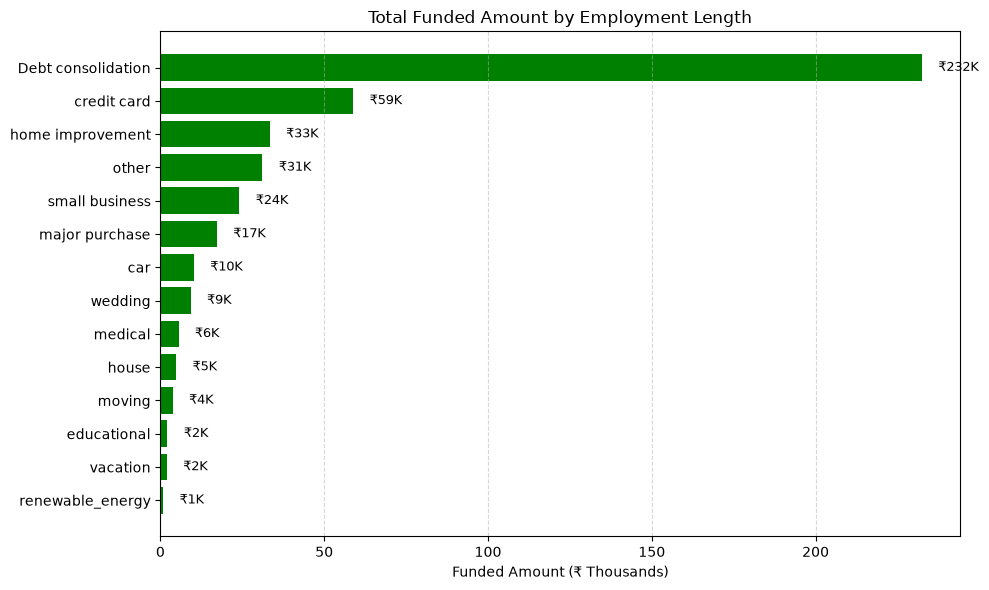

In [26]:
purpose_funding_millions = df.groupby('purpose')['loan_amount'].sum().sort_values()/1000000

plt.figure(figsize=(10, 6))
bars = plt.barh(purpose_funding_millions.index, purpose_funding_millions ,color='green')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 5, bar.get_y() + bar.get_height() / 2,
             f"₹{width:,.0f}K", va='center', fontsize=9)

plt.xlabel("Funded Amount (₹ Thousands)")
plt.title("Total Funded Amount by Loan Purpose")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 7) Home Ownership By Funded Amount

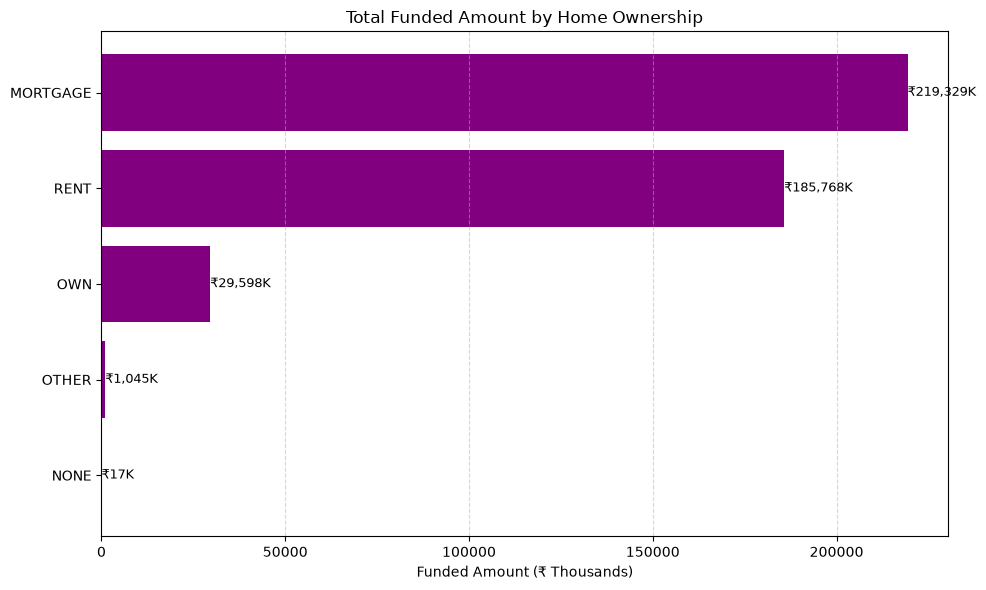

In [28]:
home_funding = df.groupby('home_ownership')['loan_amount'].sum().sort_values()/1000

plt.figure(figsize=(10, 6))
bars = plt.barh(home_funding.index, home_funding, color='purple')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 5, bar.get_y() + bar.get_height() / 2,
             f"₹{width:,.0f}K", va='center', fontsize=9)

plt.xlabel("Funded Amount (₹ Thousands)")
plt.title("Total Funded Amount by Home Ownership")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()